In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

project_root = Path.cwd().parent
data_path = (
    project_root
    / "data"
    / "processed"
    / "apl_logistics_cleaned.csv"
)

df = pd.read_csv(data_path)

print("Product & Category Performance Analytics")
print("Dataset loaded successfully!")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Product & Category Performance Analytics
Dataset loaded successfully!
Rows: 180519
Columns: 40


In [2]:
category_summary = df.groupby("Category Name").agg(
    Total_Gross_Sales=("Sales", "sum"),
    Total_Net_Sales=("Order Item Total", "sum"),
    Total_Profit=("Order Profit Per Order", "sum"),
    Total_Discounts=("Order Item Discount", "sum"),
    Units_Sold=("Order Item Quantity", "sum")
).reset_index()

category_summary["Profit_Margin_Percent"] = (
    category_summary["Total_Profit"]
    / category_summary["Total_Net_Sales"]
) * 100

print("Total Product Categories:", len(category_summary))

display(
    category_summary.sort_values(
        by="Total_Profit",
        ascending=False
    ).head(10).round(2)
)

Total Product Categories: 50


,Category Name,Total_Gross_Sales,Total_Net_Sales,Total_Profit,Total_Discounts,Units_Sold,Profit_Margin_Percent
18,Fishing,6929653.50,6226935.12,756220.76,702728.00,17325,12.14
12,Cleats,4431942.66,3982856.45,494636.92,449091.67,73734,12.42
9,Camping & Hiking,4118425.42,3700783.54,427455.57,417649.50,13729,11.55
10,Cardio Equipment,3694843.20,3320250.72,383011.10,374595.19,37587,11.54
47,Women's Apparel,3147800.00,2828708.50,350421.03,319091.50,62956,12.39
46,Water Sports,3113844.60,2798044.10,325146.96,315800.50,15540,11.62
30,Indoor/Outdoor Games,2888993.94,2596454.04,318451.43,292550.63,57803,12.26
34,Men's Footwear,2891757.54,2598494.44,311902.82,293263.10,22246,12.00
38,Shop By Sport,1309522.02,1177185.62,129813.96,132338.73,32726,11.03
13,Computers,663000.00,595395.00,69656.81,67605.00,442,11.70


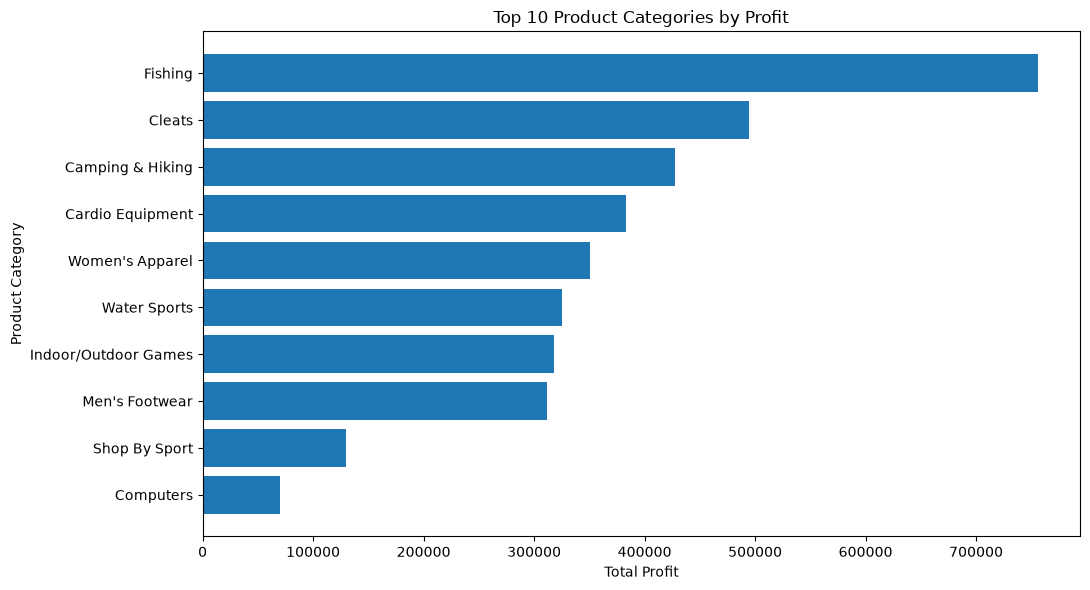

In [3]:
import matplotlib.pyplot as plt

top_categories = category_summary.nlargest(
    10, "Total_Profit"
).sort_values("Total_Profit")

plt.figure(figsize=(11, 6))

plt.barh(
    top_categories["Category Name"],
    top_categories["Total_Profit"]
)

plt.title("Top 10 Product Categories by Profit")
plt.xlabel("Total Profit")
plt.ylabel("Product Category")
plt.ticklabel_format(axis="x", style="plain")
plt.tight_layout()
plt.show()

In [6]:
product_summary = df.groupby("Product Name").agg(
    Total_Net_Sales=("Order Item Total", "sum"),
    Total_Profit=("Order Profit Per Order", "sum"),
    Total_Discounts=("Order Item Discount", "sum"),
    Units_Sold=("Order Item Quantity", "sum")
).reset_index()

product_summary["Profit_Margin_Percent"] = (
    product_summary["Total_Profit"]
    / product_summary["Total_Net_Sales"]
) * 100

print("Total Unique Products:", len(product_summary))

display(
    product_summary.sort_values(
        by="Total_Profit",
        ascending=False
    ).head(10).round(2)
)

Total Unique Products: 118


,Product Name,Total_Net_Sales,Total_Profit,Total_Discounts,Units_Sold,Profit_Margin_Percent
24,Field & Stream Sportsman 16 Gun Fire Safe,6226935.12,756220.76,702728.00,17325,12.14
71,Perfect Fitness Perfect Rip Deck,3973180.31,493828.30,447968.17,73698,12.43
21,Diamondback Women's Serene Classic Comfort Bi,3700783.54,427455.57,417649.50,13729,11.55
61,Nike Men's Free 5.0+ Running Shoe,3295693.32,379915.82,371942.59,36680,11.53
59,Nike Men's Dri-FIT Victory Golf Polo,2828708.50,350421.03,319091.50,62956,12.39
70,Pelican Sunstream 100 Kayak,2785518.00,324076.37,314327.00,15500,11.63
67,O'Brien Men's Neoprene Life Vest,2596454.04,318451.43,292550.63,57803,12.26
56,Nike Men's CJ Elite 2 TD Football Cleat,2598494.44,311902.82,293263.10,22246,12.00
102,Under Armour Girls' Toddler Spine Surge Runni,1140770.95,126278.51,128314.03,31735,11.07
18,Dell Laptop,595395.00,69656.81,67605.00,442,11.70


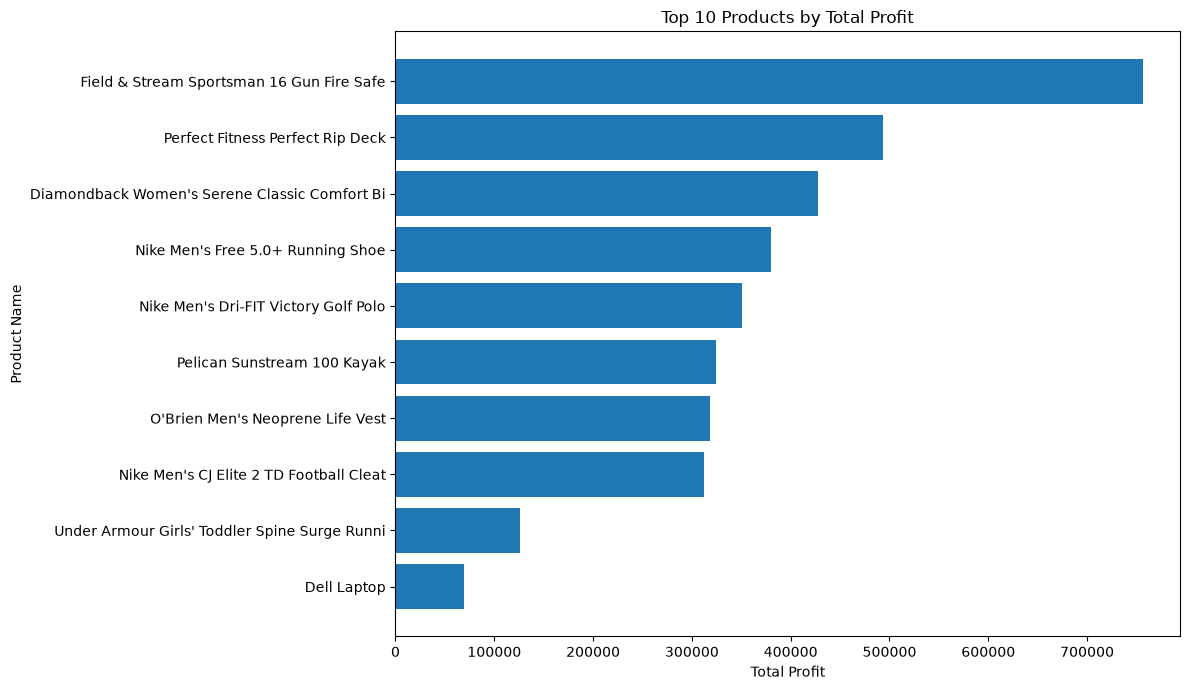

In [7]:
import matplotlib.pyplot as plt

top_products = product_summary.nlargest(
    10, "Total_Profit"
).sort_values("Total_Profit")

plt.figure(figsize=(12, 7))

plt.barh(
    top_products["Product Name"],
    top_products["Total_Profit"]
)

plt.title("Top 10 Products by Total Profit")
plt.xlabel("Total Profit")
plt.ylabel("Product Name")
plt.ticklabel_format(axis="x", style="plain")
plt.tight_layout()
plt.show()

In [18]:
print("10 Products with Lowest Profit Margins:")

display(
    product_summary.sort_values(
        by="Profit_Margin_Percent",
        ascending=True
    ).head(10).round(2)
)

10 Products with Lowest Profit Margins:


,Product Name,Total_Net_Sales,Total_Profit,Total_Discounts,Units_Sold,Profit_Margin_Percent
9,Bushnell Pro X7 Jolt Slope Rangefinder,6062.89,-255.95,537.00,11,-4.22
77,SOLE E35 Elliptical,26409.85,-965.12,3590.00,15,-3.65
76,SOLE E25 Elliptical,9414.90,-169.56,585.00,10,-1.80
36,GoPro HERO3+ Black Edition Camera,11601.68,245.63,1198.00,32,2.12
30,Garmin Forerunner 910XT GPS Watch,12593.65,391.13,1406.00,35,3.11
20,Diamondback Girls' Clarity 24 Hybrid Bike 201,7624.22,284.42,775.50,28,3.73
62,Nike Men's Free TR 5.0 TB Training Shoe,18519.61,714.43,2078.37,206,3.86
13,Cleveland Golf Women's 588 RTX CB Satin Chrom,7538.30,370.61,861.00,70,4.92
48,Men's gala suit,39365.71,2006.04,4491.21,208,5.10
37,GolfBuddy VT3 GPS Watch,10637.41,569.02,1162.00,59,5.35


In [19]:
print("Available columns:")
print(product_summary.columns.tolist())

Available columns:
['Product Name', 'Total_Net_Sales', 'Total_Profit', 'Total_Discounts', 'Units_Sold', 'Profit_Margin_Percent']


In [20]:
display(
    product_summary.nsmallest(
        10, "Profit_Margin_Percent"
    ).round(2)
)

,Product Name,Total_Net_Sales,Total_Profit,Total_Discounts,Units_Sold,Profit_Margin_Percent
9,Bushnell Pro X7 Jolt Slope Rangefinder,6062.89,-255.95,537.00,11,-4.22
77,SOLE E35 Elliptical,26409.85,-965.12,3590.00,15,-3.65
76,SOLE E25 Elliptical,9414.90,-169.56,585.00,10,-1.80
36,GoPro HERO3+ Black Edition Camera,11601.68,245.63,1198.00,32,2.12
30,Garmin Forerunner 910XT GPS Watch,12593.65,391.13,1406.00,35,3.11
20,Diamondback Girls' Clarity 24 Hybrid Bike 201,7624.22,284.42,775.50,28,3.73
62,Nike Men's Free TR 5.0 TB Training Shoe,18519.61,714.43,2078.37,206,3.86
13,Cleveland Golf Women's 588 RTX CB Satin Chrom,7538.30,370.61,861.00,70,4.92
48,Men's gala suit,39365.71,2006.04,4491.21,208,5.10
37,GolfBuddy VT3 GPS Watch,10637.41,569.02,1162.00,59,5.35


In [3]:
import pandas as pd
from pathlib import Path

project_root = Path.cwd().parent
data_path = (
    project_root
    / "data"
    / "processed"
    / "apl_logistics_cleaned.csv"
)

df = pd.read_csv(data_path)

product_summary = df.groupby("Product Name").agg(
    Total_Net_Sales=("Order Item Total", "sum"),
    Total_Profit=("Order Profit Per Order", "sum"),
    Total_Discounts=("Order Item Discount", "sum"),
    Units_Sold=("Order Item Quantity", "sum")
).reset_index()

product_summary["Profit_Margin_Percent"] = (
    product_summary["Total_Profit"]
    / product_summary["Total_Net_Sales"]
) * 100

print("Product summary recreated successfully!")
print("Unique products:", len(product_summary))

Product summary recreated successfully!
Unique products: 118


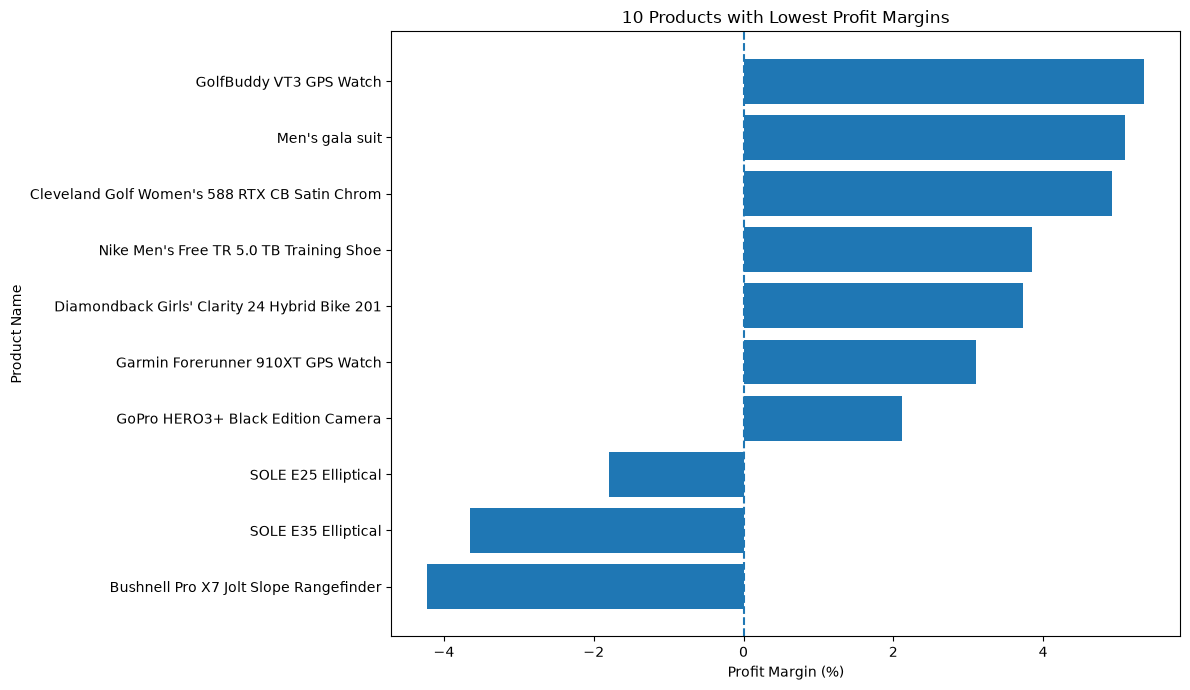

In [4]:
import matplotlib.pyplot as plt

lowest_margin_products = product_summary.nsmallest(
    10, "Profit_Margin_Percent"
).sort_values("Profit_Margin_Percent")

plt.figure(figsize=(12, 7))
plt.barh(
    lowest_margin_products["Product Name"],
    lowest_margin_products["Profit_Margin_Percent"]
)

plt.axvline(x=0, linestyle="--")
plt.title("10 Products with Lowest Profit Margins")
plt.xlabel("Profit Margin (%)")
plt.ylabel("Product Name")
plt.tight_layout()
plt.show()